In [ ]:
!pip install pandas
!pip install numpy
!pip install matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
import joblib


from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
from google.colab import files

uploaded = files.upload()

for nom_fichier in uploaded.keys():
    df = pd.read_csv(nom_fichier)

df.head()

Saving dataset-6ab989b678d90892980305.csv to dataset-6ab989b678d90892980305.csv


,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084
1,C10002,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597
2,C10003,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742
3,C10004,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000
4,C10005,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763


Analyse exploratoire des données (EDA)

In [ ]:
df.shape

(8950, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CUST_ID                 8950 non-null   object 
 1   BALANCE                 8950 non-null   float64
 2   PURCHASES               8950 non-null   float64
 3   ONEOFF_PURCHASES        8950 non-null   float64
 4   INSTALLMENTS_PURCHASES  8950 non-null   float64
 5   CASH_ADVANCE            8950 non-null   float64
 6   CREDIT_LIMIT            8949 non-null   float64
 7   PAYMENTS                8950 non-null   float64
dtypes: float64(7), object(1)
memory usage: 559.5+ KB


In [ ]:
df.isnull().sum()

,0
CUST_ID,0
BALANCE,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
CREDIT_LIMIT,1
PAYMENTS,0


In [ ]:
df.duplicated().sum()

np.int64(0)

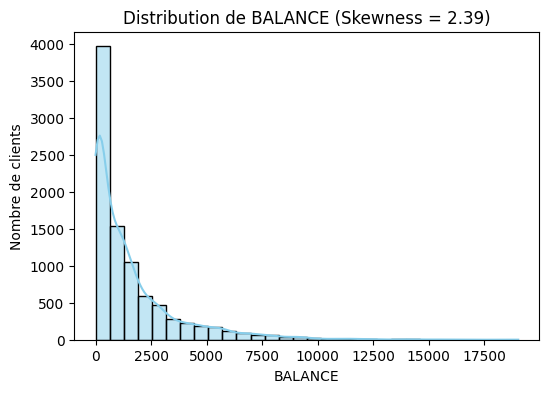

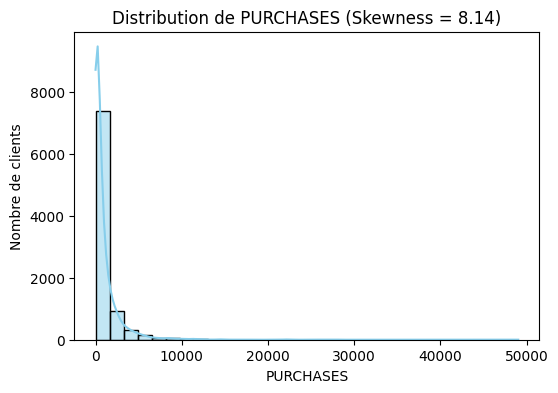

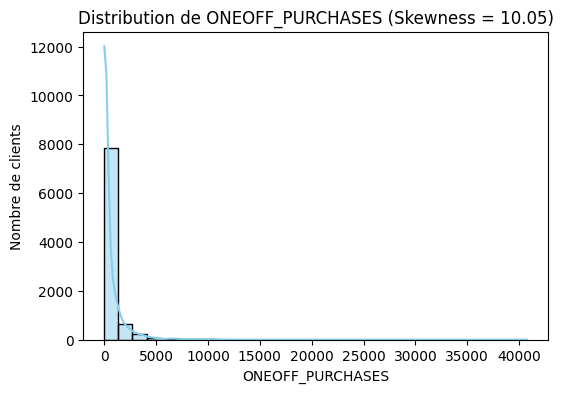

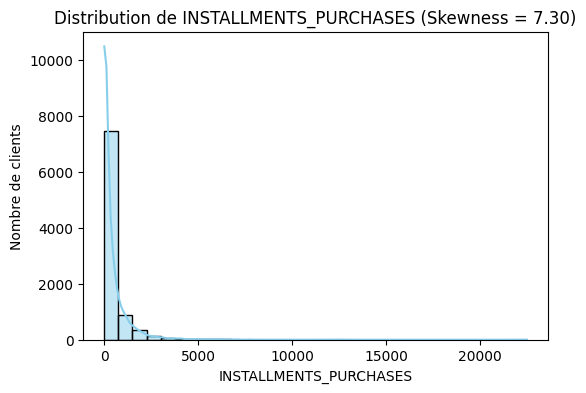

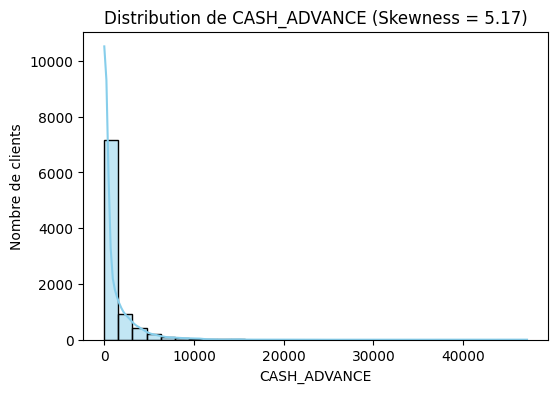

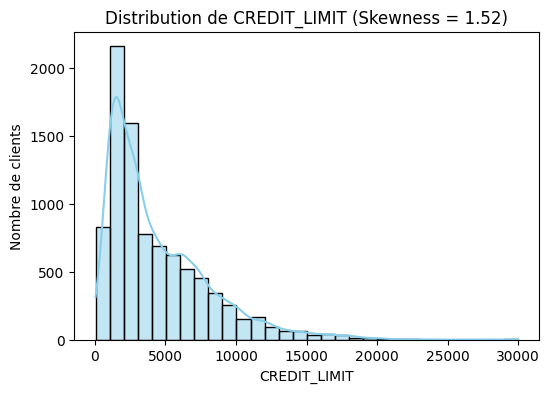

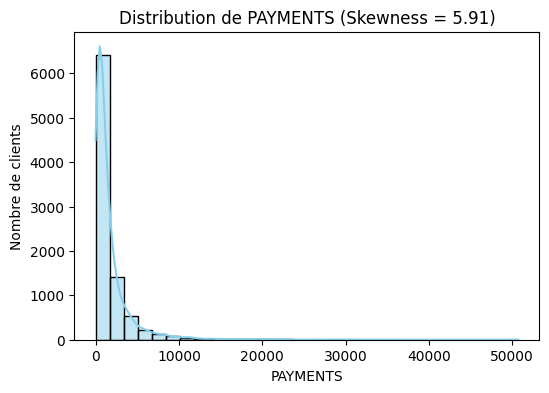

In [ ]:

numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

for col in numeric_cols:

    skew = df[col].skew()

    plt.figure(figsize=(6, 4))

    sns.histplot(df[col], bins=30, kde=True,color='skyblue')

    plt.title(f"Distribution de {col} (Skewness = {skew:.2f})")
    plt.xlabel(col)
    plt.ylabel("Nombre de clients")

    plt.show()

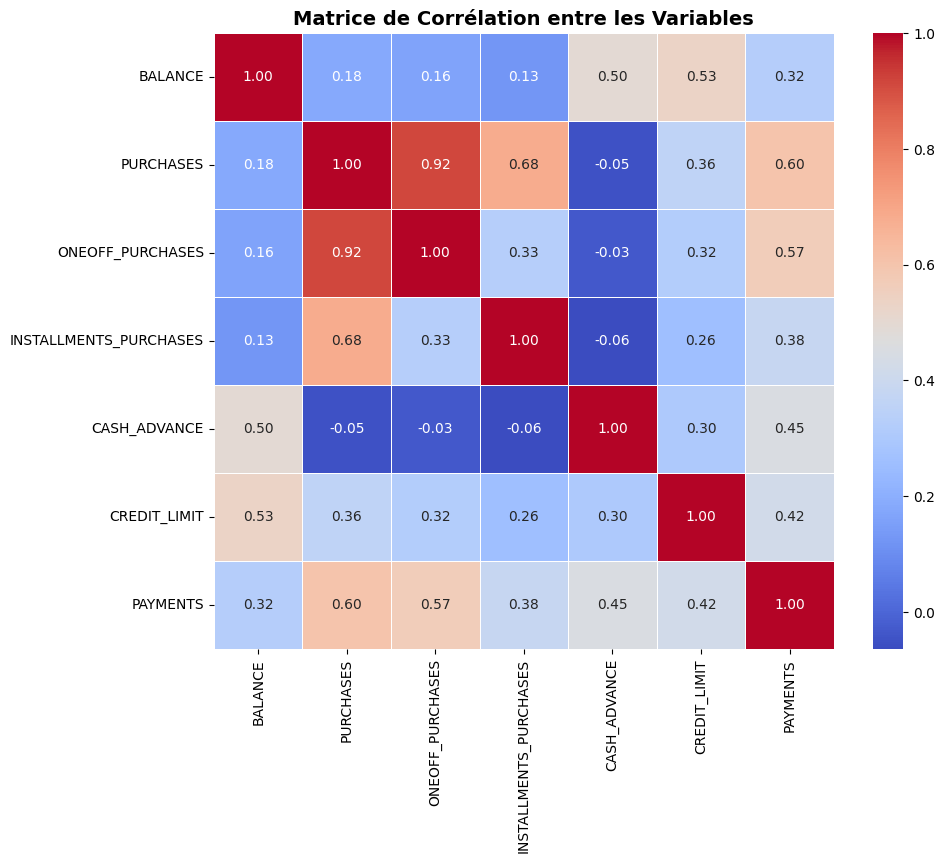

In [ ]:

numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5
)

plt.title("Matrice de Corrélation entre les Variables", fontsize=14, fontweight='bold')

plt.show()

In [ ]:

numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

outliers_data = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    seuil_inferieur = Q1 - 1.5 * IQR
    seuil_superieur = Q3 + 1.5 * IQR

    nb_outliers = df[(df[col] < seuil_inferieur) | (df[col] > seuil_superieur)]
    print(f"{col} : {len(nb_outliers)} anomalies ")




BALANCE : 695 anomalies 
PURCHASES : 808 anomalies 
ONEOFF_PURCHASES : 1013 anomalies 
INSTALLMENTS_PURCHASES : 867 anomalies 
CASH_ADVANCE : 1030 anomalies 
CREDIT_LIMIT : 248 anomalies 
PAYMENTS : 808 anomalies 


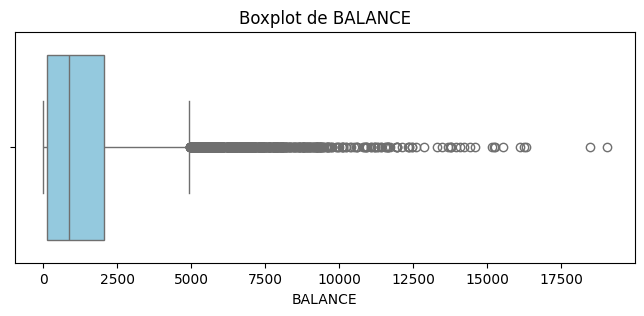

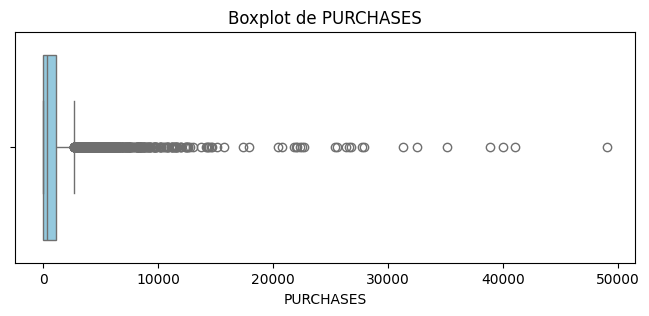

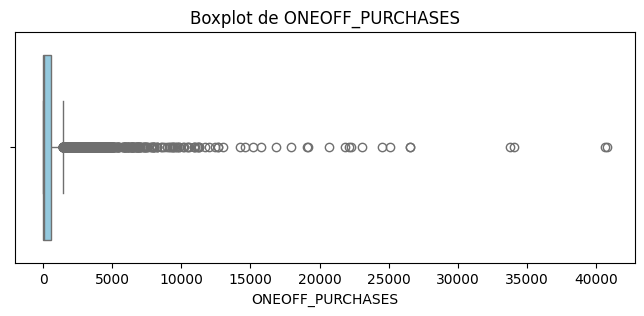

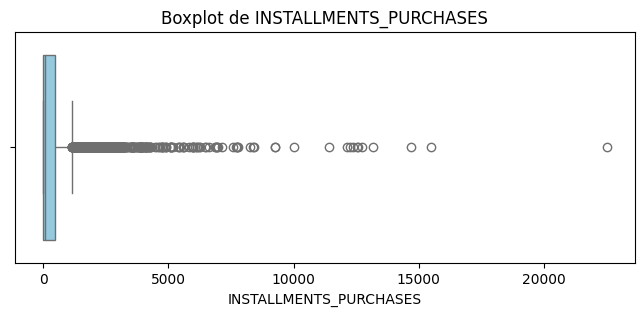

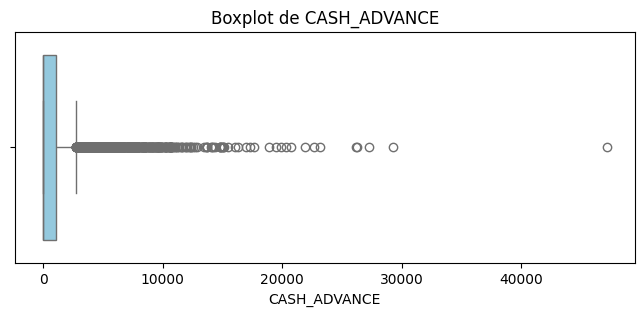

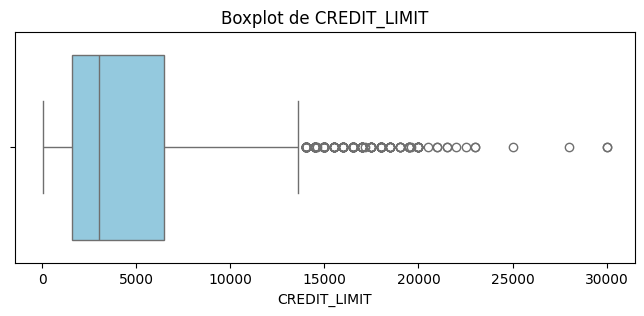

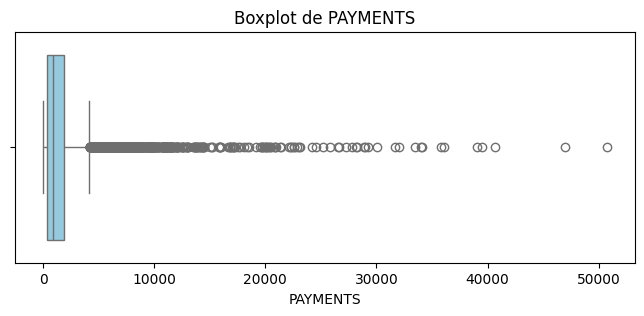

In [ ]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)

    plt.show()

In [ ]:
df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].median())

df_clean = df.drop_duplicates()

df_clean = df_clean.drop(columns=['CUST_ID'])

df_clean.to_csv('df_clean.csv', index=False)

print("Nombre valeurs manquantes :", df_clean.isnull().sum())

df_clean.head()

Nombre valeurs manquantes : BALANCE                   0
PURCHASES                 0
ONEOFF_PURCHASES          0
INSTALLMENTS_PURCHASES    0
CASH_ADVANCE              0
CREDIT_LIMIT              0
PAYMENTS                  0
dtype: int64


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084
1,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597
2,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742
3,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000
4,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763


In [ ]:
df_prepare_clustering = df_clean.copy()

cols_to_transform = df_prepare_clustering.columns

df_prepare_clustering[cols_to_transform] = np.log1p(df_prepare_clustering[cols_to_transform])

print("skewness avant")
print(df_clean.skew().round(2))

print("\n skewness apres transformation logarithmique")
print(df_prepare_clustering.skew().round(2))

df_prepare_clustering.head()

skewness avant
BALANCE                    2.39
PURCHASES                  8.14
ONEOFF_PURCHASES          10.05
INSTALLMENTS_PURCHASES     7.30
CASH_ADVANCE               5.17
CREDIT_LIMIT               1.52
PAYMENTS                   5.91
dtype: float64

 skewness apres transformation logarithmique
BALANCE                  -0.86
PURCHASES                -0.76
ONEOFF_PURCHASES          0.19
INSTALLMENTS_PURCHASES   -0.02
CASH_ADVANCE              0.26
CREDIT_LIMIT             -0.10
PAYMENTS                 -1.78
dtype: float64


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,3.735304,4.568506,0.000000,4.568506,0.000000,6.908755,5.312231
1,8.071989,0.000000,0.000000,0.000000,8.770896,8.853808,8.319725
2,7.822504,6.651791,6.651791,0.000000,0.000000,8.922792,6.434654
3,7.419183,7.313220,7.313220,0.000000,5.331694,8.922792,0.000000
4,6.707735,2.833213,2.833213,0.000000,0.000000,7.090910,6.521114


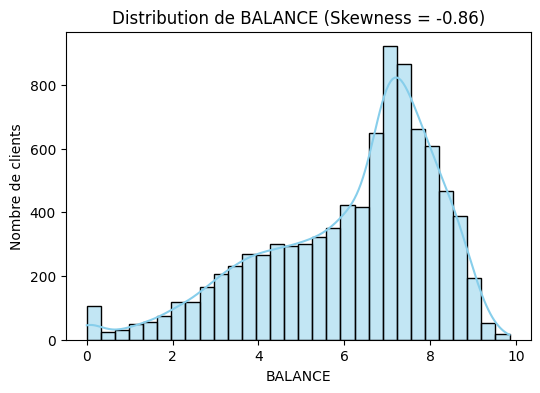

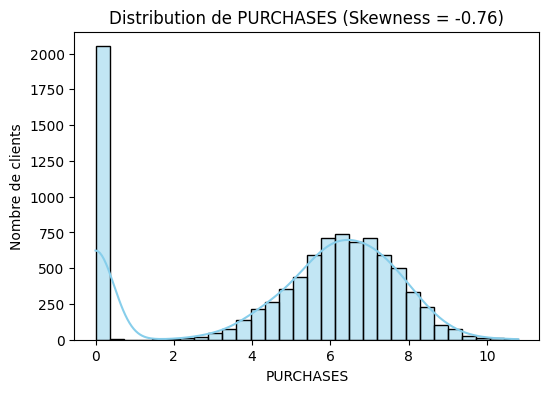

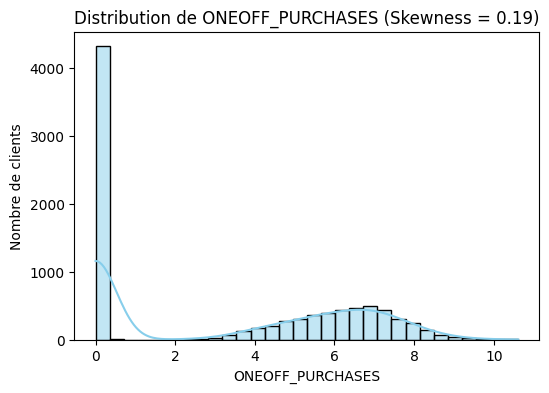

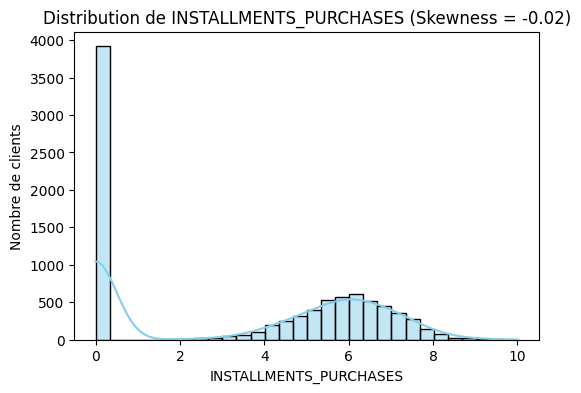

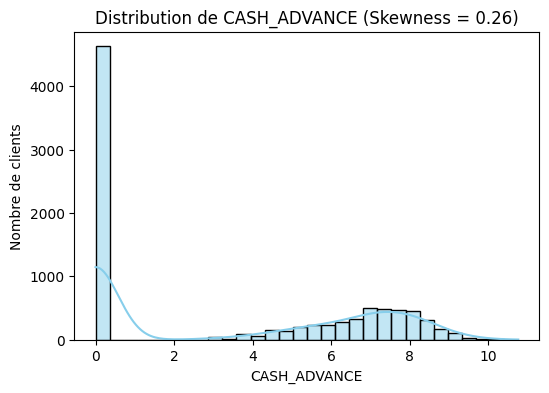

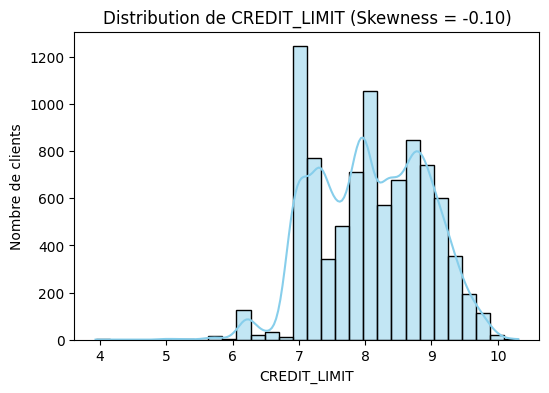

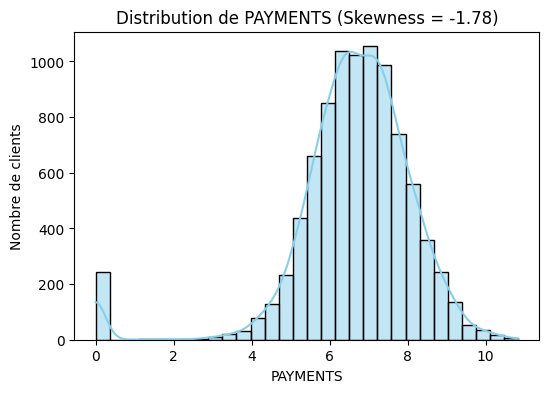

In [ ]:
numeric_cols = df_prepare_clustering.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:

    skew = df_prepare_clustering[col].skew()

    plt.figure(figsize=(6, 4))

    sns.histplot(df_prepare_clustering[col], bins=30, kde=True,color='skyblue')

    plt.title(f"Distribution de {col} (Skewness = {skew:.2f})")
    plt.xlabel(col)
    plt.ylabel("Nombre de clients")

    plt.show()

In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_prepare_clustering)
df_scaled = pd.DataFrame(scaled_data, columns=df_prepare_clustering.columns)
df_scaled

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,-1.205218,-0.113532,-0.987090,0.394480,-0.930733,-1.447163,-0.824484
1,0.948918,-1.679855,-0.987090,-1.087454,1.528788,0.926060,1.065033
2,0.824993,0.600727,1.062022,-1.087454,-0.930733,1.010229,-0.119300
3,0.624653,0.827499,1.265778,-1.087454,0.564372,1.010229,-4.161996
4,0.271260,-0.708481,-0.114307,-1.087454,-0.930733,-1.224909,-0.064979
...,...,...,...,...,...,...,...
8945,-1.379634,0.266574,-0.987090,0.754107,-0.930733,-1.447163,-0.525121
8946,-1.568051,0.276841,-0.987090,0.763821,-0.930733,-1.447163,-0.628912
8947,-1.473834,0.027374,-0.987090,0.527794,-0.930733,-1.447163,-1.391318
8948,-1.733775,-1.679855,-0.987090,-1.087454,0.086038,-2.291676,-1.661097


In [ ]:
pca = PCA()

pca_data = pca.fit_transform(df_scaled)

variance_expliquee = pca.explained_variance_ratio_ * 100
variance_cumulee = np.cumsum(variance_expliquee)

df_pca_summary = pd.DataFrame({
    'Composante': [f'PC{i+1}' for i in range(len(variance_expliquee))],
    'Variance explique (%)': variance_expliquee.round(2),
    'Variance cumule (%)': variance_cumulee.round(2)
})

display(df_pca_summary)

seuil = 80.0

n_components_min = np.argmax(variance_cumulee >= seuil) + 1

print(f"le nombre de composantes qui depasse un seuil de 80 % : {n_components_min}")
print(f"Variance cumule demande :{variance_cumulee[n_components_min - 1]:.2f}%")

,Composante,Variance explique (%),Variance cumule (%)
0,PC1,35.37,35.37
1,PC2,29.26,64.62
2,PC3,11.40,76.02
3,PC4,10.01,86.03
4,PC5,7.62,93.65
5,PC6,4.97,98.62
6,PC7,1.38,100.00


le nombre de composantes qui depasse un seuil de 80 % : 4
Variance cumule demande :86.03%


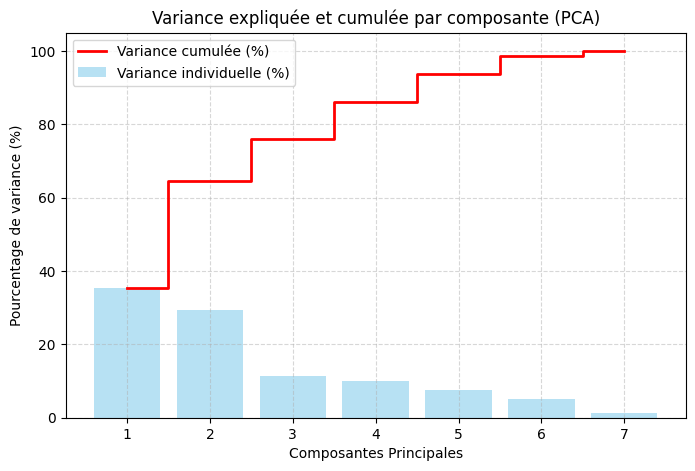

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(range(1, 8), variance_expliquee, alpha=0.6, label='Variance individuelle (%)', color='skyblue')
plt.step(range(1, 8), variance_cumulee, where='mid', label='Variance cumulée (%)', color='red', linewidth=2)

plt.xlabel('Composantes Principales')
plt.ylabel('Pourcentage de variance (%)')
plt.title('Variance expliquée et cumulée par composante (PCA)')
plt.xticks(range(1, 8))
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
resultats = []

for n_comp in range(2, 6):

    pca = PCA(n_components=n_comp, random_state=42)
    df_pca = pca.fit_transform(df_scaled)

    for k in range(2, 8):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(df_pca)

        inertie = kmeans.inertia_
        silhouette = silhouette_score(df_pca, labels)

        resultats.append({
            'Composantes PCA': n_comp,
            'k (Clusters)': k,
            'Inertie (WSSE)': round(inertie, 2),
            'Score Silhouette': round(silhouette, 4)
        })

df_grid = pd.DataFrame(resultats)
display(df_grid)

,Composantes PCA,k (Clusters),Inertie (WSSE),Score Silhouette
0,2,2,23546.23,0.4309
1,2,3,13250.77,0.4487
2,2,4,10420.61,0.4228
3,2,5,8247.58,0.4101
4,2,6,6687.62,0.3945
5,2,7,5637.30,0.3984
6,3,2,30684.84,0.3679
7,3,3,20211.66,0.3826
8,3,4,16455.11,0.3887
9,3,5,13787.09,0.3908


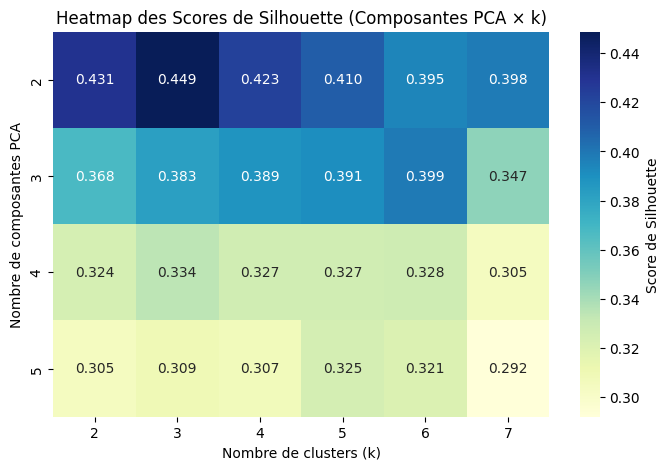

In [ ]:
pivot_df = df_grid.pivot(index='Composantes PCA', columns='k (Clusters)', values='Score Silhouette')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_df, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={'label': 'Score de Silhouette'})
plt.title("Heatmap des Scores de Silhouette (Composantes PCA × k)")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Nombre de composantes PCA")
plt.show()

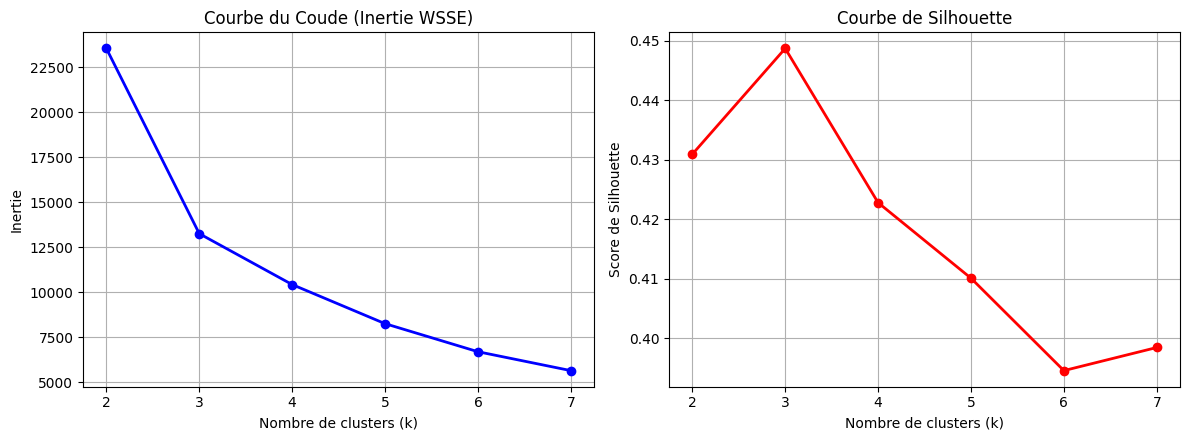

In [ ]:
pca_2 = PCA(n_components=2, random_state=42)
df_pca_2 = pca_2.fit_transform(df_scaled)

inerties = []
silhouettes = []
k_range = range(2, 8)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_pca_2)
    inerties.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(df_pca_2, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(k_range, inerties, 'bo-', linewidth=2)
axes[0].set_title("Courbe du Coude (Inertie WSSE)")
axes[0].set_xlabel("Nombre de clusters (k)")
axes[0].set_ylabel("Inertie")
axes[0].grid(True)

axes[1].plot(k_range, silhouettes, 'ro-', linewidth=2)
axes[1].set_title("Courbe de Silhouette")
axes[1].set_xlabel("Nombre de clusters (k)")
axes[1].set_ylabel("Score de Silhouette")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
pca_2 = PCA(n_components=2, random_state=42)
df_pca_2 = pca_2.fit_transform(df_scaled)
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_final = kmeans_final.fit_predict(df_pca_2)
df_clean['cluster_kmeans'] = labels_final
df_clean.head()

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans
0,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084,2
1,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597,1
2,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742,0
3,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000,2
4,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763,2


In [ ]:
prop_kmeans = df_clean['cluster_kmeans'].value_counts(normalize=True) * 100
print("=== Répartition des clusters K-Means (%) ===")
print(prop_kmeans.round(2))

=== Répartition des clusters K-Means (%) ===
cluster_kmeans
0    37.80
2    35.05
1    27.15
Name: proportion, dtype: float64


In [ ]:
eps_liste = [0.3, 0.5, 0.8, 1.0]
min_samples_liste = [5, 10, 15]
composantes_liste = [2, 3, 4]

resultats = []


for n_comp in composantes_liste:

    pca = PCA(n_components=n_comp, random_state=42)
    df_pca = pca.fit_transform(df_scaled)

    for eps in eps_liste:
        for min_samples in min_samples_liste:

            dbscan = DBSCAN(eps=eps, min_samples=min_samples)
            labels = dbscan.fit_predict(df_pca)

            nb_clusters = len(set(labels)) - (1 if -1 in labels else 0)

            pct_bruit = (labels == -1).mean() * 100

            if nb_clusters >= 2:
                silhouette = silhouette_score(df_pca, labels)
            else:
                silhouette = None

            resultats.append({
                'PCA': n_comp,
                'eps': eps,
                'min_samples': min_samples,
                'nb_clusters': nb_clusters,
                'pct_bruit': round(pct_bruit, 2),
                'silhouette': round(silhouette, 4) if silhouette else None
            })


df_grid_dbscan = pd.DataFrame(resultats)



In [ ]:
df_grid_dbscan.sort_values(by="silhouette",ascending=False)

,PCA,eps,min_samples,nb_clusters,pct_bruit,silhouette
2,2,0.3,15,2,1.87,0.4281
1,2,0.3,10,3,1.03,0.3785
0,2,0.3,5,2,0.30,0.3257
14,3,0.3,15,5,11.28,0.3148
17,3,0.5,15,4,2.10,0.2995
16,3,0.5,10,5,1.14,0.2960
28,4,0.5,10,4,7.26,0.2748
29,4,0.5,15,4,9.82,0.2656
32,4,0.8,15,2,1.92,0.2395
31,4,0.8,10,3,1.16,0.2359


In [ ]:
pca_best = PCA(n_components=2, random_state=42)
df_pca_best = pca_best.fit_transform(df_scaled)

dbscan_best = DBSCAN(eps=0.3, min_samples=15)
labels_dbscan = dbscan_best.fit_predict(df_pca_best)

df_clean['cluster_dbscan'] = labels_dbscan

df_clean['est_atypique_dbscan'] = df_clean['cluster_dbscan'] == -1

df_clean[['cluster_kmeans', 'cluster_dbscan', 'est_atypique_dbscan']].head(10)

,cluster_kmeans,cluster_dbscan,est_atypique_dbscan
0,2,0,False
1,1,1,False
2,0,0,False
3,2,0,False
4,2,0,False
5,2,0,False
6,0,0,False
7,2,0,False
8,0,0,False
9,0,0,False


In [ ]:
df_clean.head()

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans,cluster_dbscan,est_atypique_dbscan
0,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084,2,0,False
1,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597,1,1,False
2,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742,0,0,False
3,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000,2,0,False
4,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763,2,0,False


In [ ]:
df_clean.loc[df_clean["est_atypique_dbscan"]==True ,['cluster_kmeans', 'cluster_dbscan', 'est_atypique_dbscan']].head(10)

,cluster_kmeans,cluster_dbscan,est_atypique_dbscan
103,2,-1,True
133,0,-1,True
138,0,-1,True
153,0,-1,True
171,0,-1,True
273,0,-1,True
312,2,-1,True
501,0,-1,True
507,0,-1,True
550,0,-1,True


In [ ]:
prop_dbscan = df_clean['cluster_dbscan'].value_counts(normalize=True) * 100
print("=== Répartition des clusters DBSCAN (%) ===")
print(prop_dbscan.round(2))

=== Répartition des clusters DBSCAN (%) ===
cluster_dbscan
 0    75.52
 1    22.61
-1     1.87
Name: proportion, dtype: float64


In [ ]:
df_clean['cluster_final'] = df_clean['cluster_kmeans']

In [ ]:
df_clean

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans,cluster_dbscan,est_atypique_dbscan,cluster_final
0,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2,0,False,2
1,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,1,1,False,1
2,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,0,0,False,0
3,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2,0,False,2
4,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2,0,False,2
...,...,...,...,...,...,...,...,...,...,...,...
8945,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2,0,False,2
8946,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2,0,False,2
8947,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2,0,False,2
8948,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2,-1,True,2


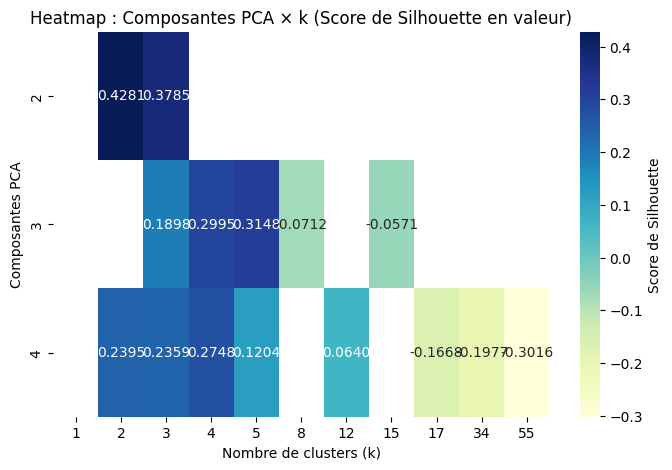

In [ ]:


# 1. Regrouper par PCA et nb_clusters (k) pour obtenir le score de Silhouette maximal
df_pca_k = df_grid_dbscan.groupby(['PCA', 'nb_clusters'])['silhouette'].max().reset_index()

# 2. Créer la table pivot : PCA en lignes, nb_clusters (k) en colonnes, silhouette en valeurs
pivot_pca_k = df_pca_k.pivot(index='PCA', columns='nb_clusters', values='silhouette')

# 3. Afficher la Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_pca_k, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'Score de Silhouette'})

plt.title('Heatmap : Composantes PCA × k (Score de Silhouette en valeur)')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Composantes PCA')

plt.show()

In [ ]:
df_scaled['Cluster'] = df_clean['cluster_final']

In [ ]:
df_means_scaled = df_scaled.groupby('Cluster').mean()

print("Moyennes par cluster standardise")
display(df_means_scaled.round(2))

Moyennes par cluster standardise


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
Cluster,,,,,,,
0,0.46,0.78,0.87,0.48,-0.02,0.60,0.57
1,0.49,-1.40,-0.80,-1.02,1.00,-0.12,-0.01
2,-0.87,0.24,-0.33,0.28,-0.75,-0.56,-0.61


In [ ]:
df_clean

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans,cluster_dbscan,est_atypique_dbscan,cluster_final
0,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2,0,False,2
1,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,1,1,False,1
2,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,0,0,False,0
3,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2,0,False,2
4,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2,0,False,2
...,...,...,...,...,...,...,...,...,...,...,...
8945,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2,0,False,2
8946,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2,0,False,2
8947,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2,0,False,2
8948,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2,-1,True,2


In [ ]:
df_means_real = df_clean.groupby('cluster_kmeans').mean()

print(" Moyennes par cluster reelles")
display(df_means_real.round(2))

 Moyennes par cluster reelles


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_dbscan,est_atypique_dbscan,cluster_final
cluster_kmeans,,,,,,,,,,
0,2266.79,2203.38,1414.47,789.14,1096.99,6531.34,2893.90,-0.02,0.02,0.0
1,2174.73,23.79,19.03,4.81,2007.25,3980.96,1629.68,0.81,0.01,1.0
2,334.37,467.60,150.12,318.04,54.87,2695.12,561.51,-0.02,0.03,2.0


In [ ]:
mapping_clusters = {
    0: "Clients Premium",
    1: "Clients a Risque",
    2: "Clients a Faible Activite"
}

df_clean['target'] = df_clean['cluster_kmeans'].map(mapping_clusters)

In [ ]:
df_clean

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans,cluster_dbscan,est_atypique_dbscan,cluster_final,target
0,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2,0,False,2,Clients a Faible Activite
1,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,1,1,False,1,Clients a Risque
2,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,0,0,False,0,Clients Premium
3,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2,0,False,2,Clients a Faible Activite
4,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2,0,False,2,Clients a Faible Activite
...,...,...,...,...,...,...,...,...,...,...,...,...
8945,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2,0,False,2,Clients a Faible Activite
8946,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2,0,False,2,Clients a Faible Activite
8947,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2,0,False,2,Clients a Faible Activite
8948,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2,-1,True,2,Clients a Faible Activite


In [ ]:
X = df_clean.drop(columns=["cluster_kmeans","cluster_dbscan","est_atypique_dbscan","cluster_final","target"])
Y = df_clean["target"]

In [ ]:
X_train, X_test,y_train, y_test = train_test_split(X,Y,train_size=0.8,random_state=1)

In [ ]:

models = {
    "Random Forest": RandomForestClassifier(random_state=1),
    "SVM": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=1),
    "Logistic Regression": LogisticRegression(max_iter=1000)
}

In [ ]:
pipelines = {}

for nom, modele in models.items():

    pipelines[nom] = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", modele)
    ])

predictions = {}

for nom, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predictions[nom] = pipeline.predict(X_test)


print(pipelines)


{'Random Forest': Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', RandomForestClassifier(random_state=1))]), 'SVM': Pipeline(steps=[('scaler', StandardScaler()), ('classifier', SVC())]), 'Decision Tree': Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', DecisionTreeClassifier(random_state=1))]), 'Logistic Regression': Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])}


In [ ]:
resultats = []

for nom in pipelines:

    y_pred = predictions[nom]

    resultats.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-score": f1_score(y_test, y_pred, average="weighted")
    })

In [ ]:
df_resultat = pd.DataFrame(resultats)
df_resultat

,Modèle,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.964804,0.964869,0.964804,0.964818
1,SVM,0.917318,0.919221,0.917318,0.917436
2,Decision Tree,0.938547,0.938996,0.938547,0.938611
3,Logistic Regression,0.910615,0.911403,0.910615,0.910574


In [ ]:
parametres = {
    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 5, 10]
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"]
    },

    "Decision Tree": {
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_split": [2, 5, 10]
    },

    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10]
    }
}

In [ ]:
grid_models = {}

for nom, pipeline in pipelines.items():

    grid = GridSearchCV(
        pipeline,
        parametres[nom],
        cv=5,
        scoring="f1_macro"
    )

    grid.fit(X_train, y_train,)
    grid_models[nom] = grid

    # grid_models[nom] =     {
    #     "best estimator": grid.best_estimator_,
    #     "best params": grid.best_params_,
    #     "best score": grid.best_score_}

    print("Meilleurs parametre :",grid.best_params_)
    print("best estimator :" ,grid.best_estimator_)
    print("Meilleur score :", grid.best_score_)


Meilleurs parametre : {'classifier__max_depth': None, 'classifier__n_estimators': 200}
best estimator : Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 RandomForestClassifier(n_estimators=200, random_state=1))])
Meilleur score : 0.9677159445324944
Meilleurs parametre : {'classifier__C': 10, 'classifier__kernel': 'rbf'}
best estimator : Pipeline(steps=[('scaler', StandardScaler()), ('classifier', SVC(C=10))])
Meilleur score : 0.9403859115796364
Meilleurs parametre : {'classifier__max_depth': 10, 'classifier__min_samples_split': 5}
best estimator : Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 DecisionTreeClassifier(max_depth=10, min_samples_split=5,
                                        random_state=1))])
Meilleur score : 0.9418184947444376
Meilleurs parametre : {'classifier__C': 10}
best estimator : Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegressi

In [ ]:
display(grid_models)

{'Random Forest': GridSearchCV(cv=5,
              estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                        ('classifier',
                                         RandomForestClassifier(random_state=1))]),
              param_grid={'classifier__max_depth': [None, 5, 10],
                          'classifier__n_estimators': [100, 200]},
              scoring='f1_macro'),
 'SVM': GridSearchCV(cv=5,
              estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                        ('classifier', SVC())]),
              param_grid={'classifier__C': [0.1, 1, 10],
                          'classifier__kernel': ['linear', 'rbf']},
              scoring='f1_macro'),
 'Decision Tree': GridSearchCV(cv=5,
              estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                        ('classifier',
                                         DecisionTreeClassifier(random_state=1))]),
              para

In [ ]:
results=[]
for nom , grid in grid_models.items():
  y_pred=grid.predict(X_test)

  results.append({
      "modele":nom,
      "matrice de confusion":confusion_matrix(y_test,y_pred),
      "Accuracy  ":accuracy_score(y_test, y_pred),
      "Precision ": precision_score(y_test, y_pred,average="weighted"),
      "Recall ": recall_score(y_test, y_pred,average="weighted"),
      "F1-score ": f1_score(y_test, y_pred,average="weighted")
  })



In [ ]:
df_result=pd.DataFrame(results)
df_result

,modele,matrice de confusion,Accuracy,Precision,Recall,F1-score
0,Random Forest,"[[667, 17, 6], [18, 591, 6], [9, 6, 470]]",0.965363,0.965387,0.965363,0.965369
1,SVM,"[[651, 25, 14], [14, 580, 21], [9, 8, 468]]",0.949162,0.949497,0.949162,0.949193
2,Decision Tree,"[[637, 46, 7], [27, 577, 11], [13, 11, 461]]",0.935754,0.936153,0.935754,0.935838
3,Logistic Regression,"[[618, 56, 16], [32, 553, 30], [17, 9, 459]]",0.910615,0.910865,0.910615,0.910534


In [ ]:
import joblib

meilleur_score = 0
meilleur_modele = None

for nom, grid in grid_models.items():

    if grid.best_score_ > meilleur_score:
        meilleur_score = grid.best_score_
        meilleur_modele = grid.best_estimator_
        meilleur_nom = nom

joblib.dump(meilleur_modele, "meilleur_modele.joblib")

print("Meilleur modele :", meilleur_nom)
print("Meilleur score :", meilleur_score)



Meilleur modele : Random Forest
Meilleur score : 0.9677159445324944
